# 4.5 · 滚动训练 · 模型评估 · 集成 · 防过拟合

> 前面我们训练了不同模型。本节把模型"工程化"：**用滚动训练产出连续的样本外预测、建立完整的评估体系、用模型集成提升稳定性、并系统防范过拟合**。
> 这是模型能真正上线的关键环节。

## 一、为什么必须滚动训练

市场风格会变化（如 2024 年初微盘股危机、风格切换），单一模型训练一次无法长期适应。
**滚动训练（Walk-Forward）**：每隔一段时间（如每季度/半年），用截至当时的全部历史重新训练，预测下一段，再把所有样本外预测拼接起来。
- 每段预测都只用了当时可得的信息，**完全模拟真实的样本外表现**；
- 模型自动跟上最新数据。

## 二、滚动训练实测（代码在 model_lab.rolling）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from model_lab.data import build_panel, predict_ic
from model_lab.rolling import walk_forward, make_repoints
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
df = build_panel(close, F['$volume'].unstack('instrument'),
                 F['$mkt_cap_ard'].unstack('instrument'),
                 F['$pe_ttm'].unstack('instrument'),
                 F['$pb_lf'].unstack('instrument'), 1)
feat = [c for c in df.columns if c != 'label']
repoints = make_repoints(df)
print('重训点:', [str(p.date()) for p in repoints])

pred_lgb = walk_forward(df, feat, 'lgb', repoints)
pred_rd = walk_forward(df, feat, 'ridge', repoints)
ic_lgb = predict_ic(pred_lgb, df.loc[pred_lgb.index, 'label'])
ic_rd = predict_ic(pred_rd, df.loc[pred_rd.index, 'label'])
print('滚动 LightGBM 样本外 IC %.4f IR %.4f' % (ic_lgb.mean(), ic_lgb.mean()/ic_lgb.std()))
print('滚动 Ridge    样本外 IC %.4f IR %.4f' % (ic_rd.mean(), ic_rd.mean()/ic_rd.std()))

[25244:MainThread](2026-10-30 01:29:46,744) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[25244:MainThread](2026-10-30 01:29:48,160) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[25244:MainThread](2026-10-30 01:29:48,161) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


重训点: ['2023-06-28', '2023-12-28', '2024-06-28', '2024-12-28', '2025-06-28', '2025-12-28', '2026-06-28']


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 30 rounds


... (11 outputs left out)

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 30 rounds


Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 0.0815744


滚动 LightGBM 样本外 IC 0.0345 IR 0.2130
滚动 Ridge    样本外 IC 0.0379 IR 0.1681


## 三、模型评估体系

完整评估一个模型，除了 IC，还要看：
1. **IC 均值 / IR / 胜率**（核心）；
2. **IC 累积曲线**：是否稳定向上（不被少数极端日贡献）；
3. **预测值分布**：是否合理（不能全挤在一个值）；
4. **分层单调性**：按预测值分组，收益是否单调（预测高的组确实收益高）。

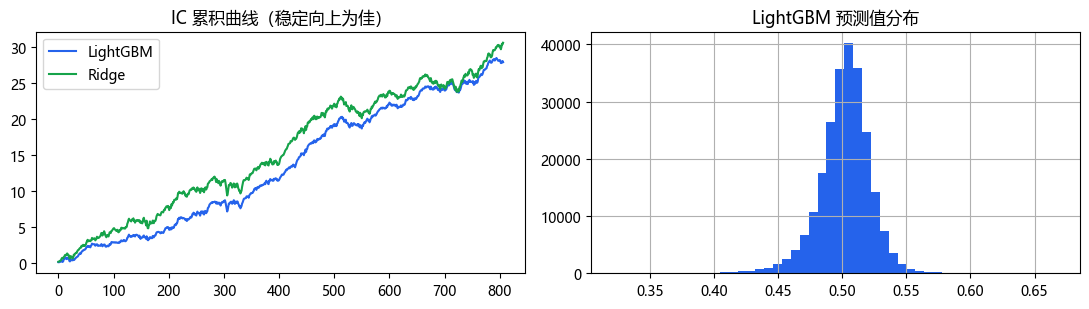

In [2]:
# IC 累积曲线
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(ic_lgb.index, ic_lgb.cumsum(), label='LightGBM', color='#2563eb')
ax[0].plot(ic_rd.index, ic_rd.cumsum(), label='Ridge', color='#16a34a')
ax[0].legend(); ax[0].set_title('IC 累积曲线（稳定向上为佳）')
# 预测值分布
pred_lgb.hist(bins=50, ax=ax[1], color='#2563eb')
ax[1].set_title('LightGBM 预测值分布')
plt.tight_layout(); plt.show()

## 四、分层单调性：预测值能否区分股票

各预测分组的平均次日收益:
grp
0    0.00054
1    0.00047
2    0.00060
3    0.00038
4    0.00069
Name: label, dtype: float32


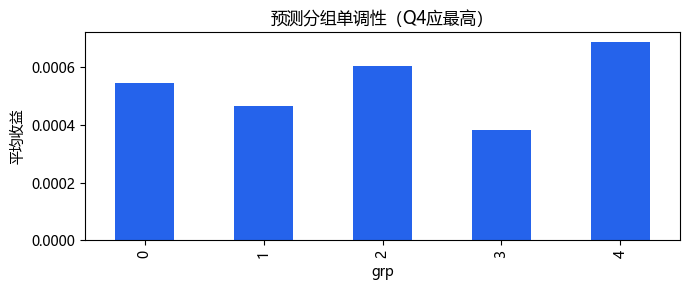

In [3]:
# 按预测值在每个截面分 5 组，看各组平均收益
d = pd.DataFrame({'pred': pred_lgb, 'label': df.loc[pred_lgb.index, 'label']})
d['grp'] = d.groupby(level='datetime')['pred'].transform(
    lambda x: pd.qcut(x.rank(method='first'), 5, labels=False, duplicates='drop'))
grp_ret = d.groupby('grp')['label'].mean()
print('各预测分组的平均次日收益:')
print(grp_ret.round(5))
grp_ret.plot(kind='bar', figsize=(7,3), color='#2563eb')
plt.title('预测分组单调性（Q4应最高）'); plt.ylabel('平均收益'); plt.tight_layout(); plt.show()

## 五、模型集成（Ensemble）

不同模型的错误往往不同，**集成能降低波动、提升稳定性**：
- **平均集成**：多个模型预测值标准化后平均（如 LightGBM + Ridge）；
- **Bagging**：同一模型不同随机种子/子样本，平均；
- **Stacking**：用一个元模型学习如何组合各模型预测。

最简单稳健的平均集成常有效。

In [4]:
# 截面标准化后平均
def cs_norm(s):
    w = s.unstack('instrument').rank(axis=1, pct=True)
    return w.stack()
p1 = cs_norm(pred_lgb); p2 = cs_norm(pred_rd)
ens = (p1 + p2) / 2
ic_ens = predict_ic(ens, df.loc[ens.index, 'label'])
print('集成模型 IC %.4f IR %.4f' % (ic_ens.mean(), ic_ens.mean()/ic_ens.std()))
print('对比 LGB IR %.4f / Ridge IR %.4f' %
      (ic_lgb.mean()/ic_lgb.std(), ic_rd.mean()/ic_rd.std()))

集成模型 IC 0.0394 IR 0.1925
对比 LGB IR 0.2130 / Ridge IR 0.1681


## 六、防过拟合体系（系统总结）

| 手段 | 作用 |
|---|---|
| 严格按时间切分、滚动训练 | 杜绝未来信息泄漏 |
| 验证集 early stopping | 防止训练过多 |
| 正则化（Ridge/L1、dropout、weight decay） | 限制复杂度 |
| 行列/特征采样 | 增加随机性 |
| 特征选择/去冗余 | 减少噪声因子 |
| 样本外 + 多区间/多股票池验证 | 确认泛化 |
| 控制试验次数、多重检验校正 | 防止数据挖掘偏差 |

> 记住：**金融数据信噪比极低，任何模型的样本内表现都要打折，样本外才是真相。**

## 七、模型监控与衰减

上线后要持续监控：
- 预测 IC 是否衰减、分布是否漂移；
- 因子重要性是否突变；
- 当模型持续低于阈值时，重新训练或淘汰。

Alpha 会随竞争和市场结构变化而衰减，模型库需要持续迭代。

## 八、模块 4 小结与面试要点

- 模型把多因子合成预测：线性（透明）→ LightGBM（主力、非线性）→ 深度学习（序列/关系）。
- 标签截面 rank 化、按时间切分、滚动训练是让模型正确工作的关键；滚动训练我们实测 IR 0.21。
- 评估看 IC/IR/累积曲线/分布/分层单调性；集成提升稳定性；防过拟合是系统工程。

**面试高频：**
- 完整描述一个多因子选股模型的搭建流程？（数据→因子→预处理→标签→滚动训练→评估→集成→组合）
- 怎么判断模型是否过拟合？（答：样本内好样本外差、IC累积不平稳；用样本外、early stop、正则）
- 模型集成为什么有效？（答：不同模型误差不同，平均降低方差）
- 滚动训练怎么实现？（答：定期重训，训练窗口向前滚动，拼接样本外预测）

## 动手练习
1. 把重训频率改成每季度，对比 IR；
2. 用 3 个不同种子的 LightGBM 做 Bagging；
3. 把模型预测送入模块 5 的组合优化。

---
模块 4「模型预测」完成。进入 **模块 5：组合构建与风险控制（均值-方差、优化器、风险模型、约束）**。